## 1. Setup and configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
CONTAMINATION = 0.06          # expected fraction of anomalous students
N_ESTIMATORS = 300            # trees in the Isolation Forest

# Set to a CSV path to use real data, e.g. "/kaggle/input/my-dataset/scores.csv".
# Leave as None to use the synthetic dataset with known, injected anomalies.
DATA_PATH = None

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Outputs will be written to:", OUT_DIR)

Outputs will be written to: /kaggle/working


# Student Performance Outlier Detection using Isolation Forest

**Course:** Pattern Recognition and Anomaly Detection (Semester 5)

**Problem statement:** Apply Isolation Forests to identify highly unusual academic score trajectories and potential data entry errors in multi-semester databases.

**Pipeline:** data preparation → feature extraction → Isolation Forest → anomaly scores → evaluation → interpretation → conclusions

### How to run on Kaggle
1. Go to **kaggle.com → Code → New Notebook → File → Import Notebook** and upload this `.ipynb`.
2. Click **Run All**. No internet or GPU is needed, and all libraries are preinstalled.
3. To use real data instead of the synthetic data, click **Add Input**, attach your dataset, and set `DATA_PATH` in the configuration cell below. The CSV needs columns `student_id, sem1, sem2, ..., semN` with scores out of 100.
4. Outputs (results CSV and plots) are saved to `/kaggle/working`, so you can download them from the **Output** tab.

## 2. Dataset

Real multi-semester student records with known errors are rarely available, so the default dataset is **synthetic**. Each student has a base ability, a slow trend over semesters and small random noise. About 6% of students then receive one of six injected anomaly types, so detection quality can be measured against known labels:

| Type | Meaning |
|---|---|
| `sudden_drop` / `sudden_spike` | abrupt, unexplained change in performance |
| `entry_error` | impossible values (0, 7.5, 150, 785, -10) |
| `digit_swap` | transposed digits, e.g. 82 → 28 |
| `flatline` | identical score every semester (copy-paste) |
| `zigzag` | erratic up-down trajectory |

In [2]:
KINDS = ["sudden_drop", "sudden_spike", "entry_error", "digit_swap", "flatline", "zigzag"]

def make_synthetic(n_students=500, n_sems=6, anomaly_frac=0.06, seed=SEED):
    rng = np.random.default_rng(seed)
    ability = rng.normal(68, 11, n_students).clip(35, 95)
    trend = rng.normal(0.5, 1.0, n_students)
    t = np.arange(n_sems)
    scores = (ability[:, None] + trend[:, None] * t
              + rng.normal(0, 3, (n_students, n_sems))).clip(20, 99)

    labels = np.zeros(n_students, dtype=int)
    kinds = np.array(["normal"] * n_students, dtype=object)
    zigzag = np.array([20, -22, 18, -20, 22, -18] * ((n_sems // 6) + 1))[:n_sems]

    for i in rng.choice(n_students, int(anomaly_frac * n_students), replace=False):
        kind = rng.choice(KINDS)
        s = rng.integers(1, n_sems - 1)
        if kind == "sudden_drop":
            scores[i, s:] -= rng.uniform(30, 45)
        elif kind == "sudden_spike":
            scores[i, s] += rng.uniform(30, 40)
        elif kind == "entry_error":
            scores[i, s] = rng.choice([0, 7.5, 150, 785, -10])
        elif kind == "digit_swap":
            scores[i, s] = int(str(abs(int(round(scores[i, s]))))[::-1])
        elif kind == "flatline":
            scores[i, :] = scores[i, 0]
        elif kind == "zigzag":
            scores[i, :] = ability[i] + zigzag
        labels[i], kinds[i] = 1, kind

    df = pd.DataFrame(scores.round(1), columns=[f"sem{k+1}" for k in range(n_sems)])
    df.insert(0, "student_id", [f"S{1000+i}" for i in range(n_students)])
    return df, labels, kinds

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)
    y_true, kinds = None, None
else:
    df, y_true, kinds = make_synthetic()

sem_cols = [c for c in df.columns if c.lower().startswith("sem")]
assert len(sem_cols) >= 3, "Need at least 3 semester columns named sem1, sem2, ..."
if "student_id" not in df.columns:
    df.insert(0, "student_id", [f"row{i}" for i in range(len(df))])

print(f"{len(df)} students, {len(sem_cols)} semesters")
df.head()

500 students, 6 semesters


,student_id,sem1,sem2,sem3,sem4,sem5,sem6
0,S1000,71.2,71.0,73.8,78.8,78.8,81.7
1,S1001,58.6,56.8,61.6,61.9,58.4,67.9
2,S1002,74.8,71.1,72.7,72.5,75.5,74.3
3,S1003,77.3,79.2,77.4,76.3,75.6,75.2
4,S1004,40.2,43.0,35.1,39.3,36.7,37.4


## 3. Data preparation and exploration

In [3]:
# Numeric coercion and median imputation of missing scores
df[sem_cols] = df[sem_cols].apply(pd.to_numeric, errors="coerce")
print("Missing values before imputation:", int(df[sem_cols].isna().sum().sum()))
df[sem_cols] = df[sem_cols].apply(lambda c: c.fillna(c.median()))

# Rule-based validation: scores outside 0-100 are definite data errors
X = df[sem_cols].to_numpy(float)
rule_out_of_range = ((X < 0) | (X > 100)).any(axis=1)
print("Students with a score outside 0-100:", int(rule_out_of_range.sum()))

df[sem_cols].describe().round(1)

Missing values before imputation: 0
Students with a score outside 0-100: 5


,sem1,sem2,sem3,sem4,sem5,sem6
count,500.0,500.0,500.0,500.0,500.0,500.0
mean,67.9,68.1,68.1,69.6,68.7,69.4
std,10.8,11.9,13.8,34.7,13.8,13.3
min,40.2,5.5,-10.0,6.5,7.0,16.8
25%,60.9,60.6,60.1,60.3,60.8,61.4
50%,68.3,68.1,68.8,69.6,70.1,70.3
75%,74.9,75.4,75.7,76.2,77.2,77.9
max,99.0,117.6,150.0,785.0,99.0,99.0


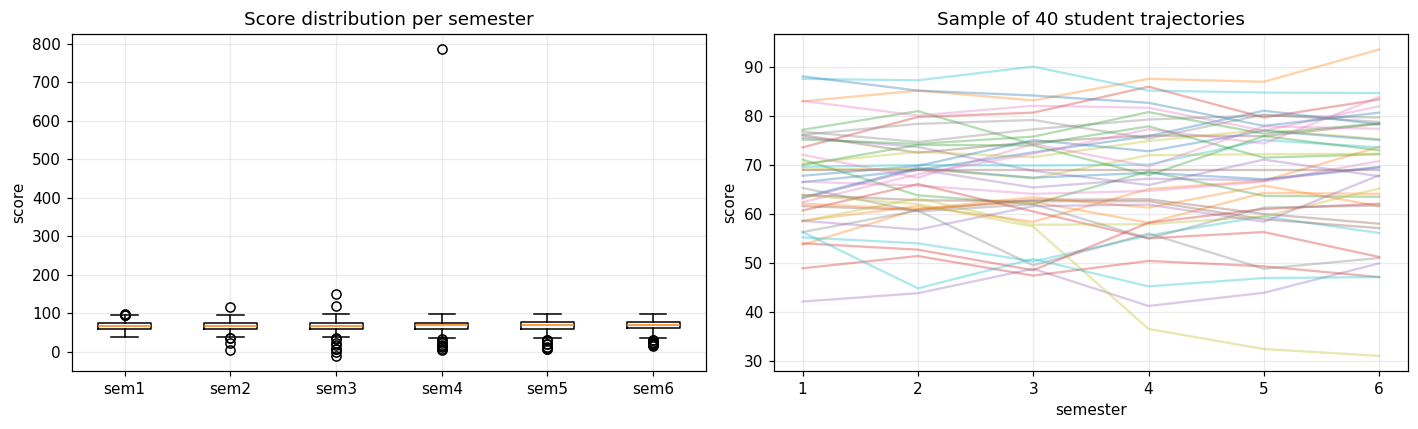

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Score distribution per semester (note the extreme points)
axes[0].boxplot([df[c] for c in sem_cols], tick_labels=sem_cols)
axes[0].set_title("Score distribution per semester")
axes[0].set_ylabel("score")
# A random sample of trajectories
rng = np.random.default_rng(0)
for i in rng.choice(len(df), 40, replace=False):
    axes[1].plot(range(1, len(sem_cols) + 1), X[i].clip(-20, 120), alpha=0.35)
axes[1].set_title("Sample of 40 student trajectories")
axes[1].set_xlabel("semester"); axes[1].set_ylabel("score")
plt.tight_layout(); plt.show()

## 4. Feature extraction

Isolation Forest works on a fixed-length feature vector, so each student's trajectory is summarised by 12 features that capture **level**, **spread**, **trend**, **jumpiness** and **suspicious repetition**. Raw semester scores alone would miss trajectory-shape anomalies such as a flatline or a zigzag.

In [5]:
def extract_features(df, sem_cols):
    x = df[sem_cols].to_numpy(float)
    t = np.arange(x.shape[1])
    d = np.diff(x, axis=1)
    slope, resid = [], []
    for row in x:
        coef = np.polyfit(t, row, 1)
        slope.append(coef[0])
        resid.append(np.max(np.abs(row - np.polyval(coef, t))))
    return pd.DataFrame({
        "mean": x.mean(1), "std": x.std(1),
        "min": x.min(1), "max": x.max(1), "range": x.max(1) - x.min(1),
        "slope": slope,
        "max_abs_jump": np.abs(d).max(1), "mean_abs_jump": np.abs(d).mean(1),
        "sign_changes": (np.diff(np.sign(d), axis=1) != 0).sum(1),
        "max_resid": resid,
        "first_last_diff": x[:, -1] - x[:, 0],
        "n_repeats": (d == 0).sum(1),
    }, index=df.index)

feats = extract_features(df, sem_cols)
feats.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean,500.0,68.62,12.76,15.08,60.66,68.95,75.76,184.95
std,500.0,4.38,12.43,0.00,2.29,3.11,3.94,268.35
min,500.0,62.92,14.03,-10.00,55.52,64.65,71.10,96.30
max,500.0,75.46,34.01,43.00,65.78,74.70,81.22,785.00
range,500.0,12.54,33.48,0.00,6.60,9.20,11.70,722.30
slope,500.0,0.30,1.98,-11.57,-0.55,0.40,1.32,21.16
max_abs_jump,500.0,9.93,33.36,0.00,5.00,6.60,8.50,720.90
mean_abs_jump,500.0,4.77,13.43,0.00,2.52,3.47,4.51,289.30
sign_changes,500.0,2.55,0.99,0.00,2.00,3.00,3.00,4.00
max_resid,500.0,6.27,27.13,0.00,2.70,3.85,4.99,589.47


## 5. Isolation Forest

Isolation Forest builds random trees that repeatedly split the data on a random feature at a random threshold. Anomalies are few and different, so they are isolated in **fewer splits** (shorter average path length) than normal points. The anomaly score is derived from that path length, and a higher score means more anomalous.

`contamination` sets the fraction of students flagged. Section 8 studies how sensitive the results are to it.

In [6]:
Z = StandardScaler().fit_transform(feats)

iso = IsolationForest(n_estimators=N_ESTIMATORS, contamination=CONTAMINATION,
                      random_state=SEED, n_jobs=-1).fit(Z)
score = -iso.score_samples(Z)                 # higher = more anomalous
pred = (iso.predict(Z) == -1).astype(int)     # 1 = flagged

print(f"Flagged {pred.sum()} of {len(df)} students ({pred.mean():.1%})")

results = df.copy()
results["anomaly_score"] = score.round(4)
results["is_anomaly"] = pred
results["rule_out_of_range"] = rule_out_of_range.astype(int)
results = results.sort_values("anomaly_score", ascending=False)
results.head(15)

Flagged 30 of 500 students (6.0%)


,student_id,sem1,sem2,sem3,sem4,sem5,sem6,anomaly_score,is_anomaly,rule_out_of_range
285,S1285,62.7,65.7,64.1,785.0,65.4,66.8,0.8347,1,1
70,S1070,53.3,52.4,150.0,55.3,50.7,46.5,0.7409,1,1
103,S1103,77.1,73.7,-10.0,75.9,77.9,79.0,0.7148,1,1
24,S1024,63.3,67.3,0.0,67.8,74.0,75.9,0.6953,1,0
490,S1490,80.3,80.4,8.0,86.2,89.1,86.6,0.6928,1,0
332,S1332,60.1,66.9,57.6,13.3,11.3,21.3,0.6866,1,0
329,S1329,62.7,61.1,17.9,17.8,14.1,20.7,0.6814,1,0
297,S1297,65.4,68.7,68.2,68.9,7.0,71.5,0.6802,1,0
457,S1457,53.6,63.3,72.6,7.5,64.7,75.1,0.6758,1,0
320,S1320,96.6,54.6,94.6,56.6,98.6,58.6,0.6705,1,0


## 6. Visualisation of anomalies

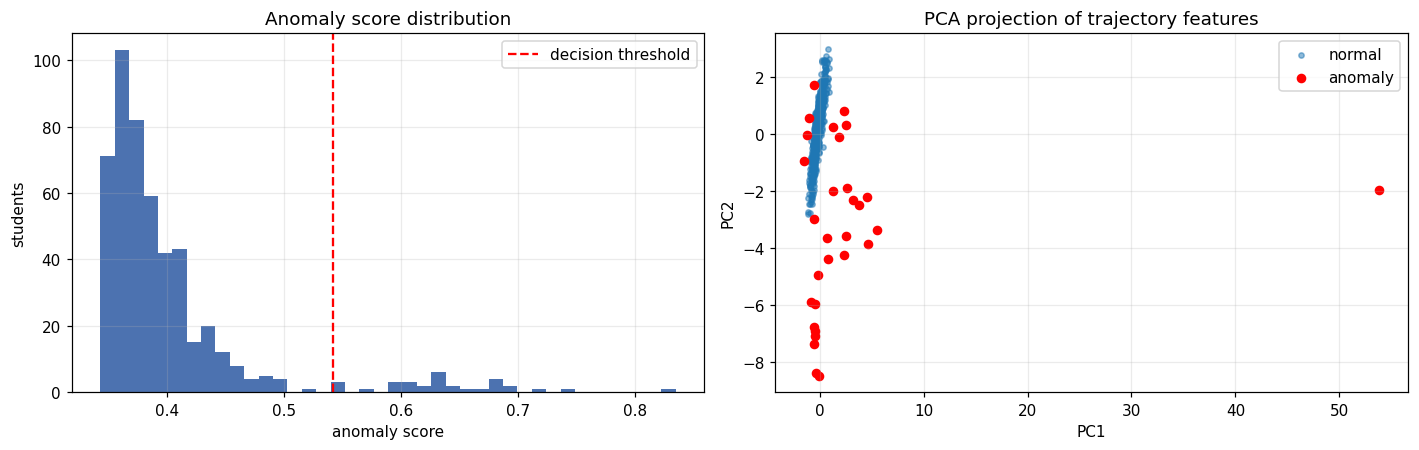

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# (a) Score distribution with the decision threshold
axes[0].hist(score, bins=40, color="#4C72B0")
axes[0].axvline(np.sort(score)[-pred.sum()], color="red", ls="--", label="decision threshold")
axes[0].set(title="Anomaly score distribution", xlabel="anomaly score", ylabel="students")
axes[0].legend()

# (b) PCA projection of the feature space
P = PCA(2, random_state=SEED).fit_transform(Z)
axes[1].scatter(P[pred == 0, 0], P[pred == 0, 1], s=12, alpha=0.5, label="normal")
axes[1].scatter(P[pred == 1, 0], P[pred == 1, 1], s=28, c="red", label="anomaly")
axes[1].set(title="PCA projection of trajectory features", xlabel="PC1", ylabel="PC2")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/score_and_pca.png", dpi=150); plt.show()

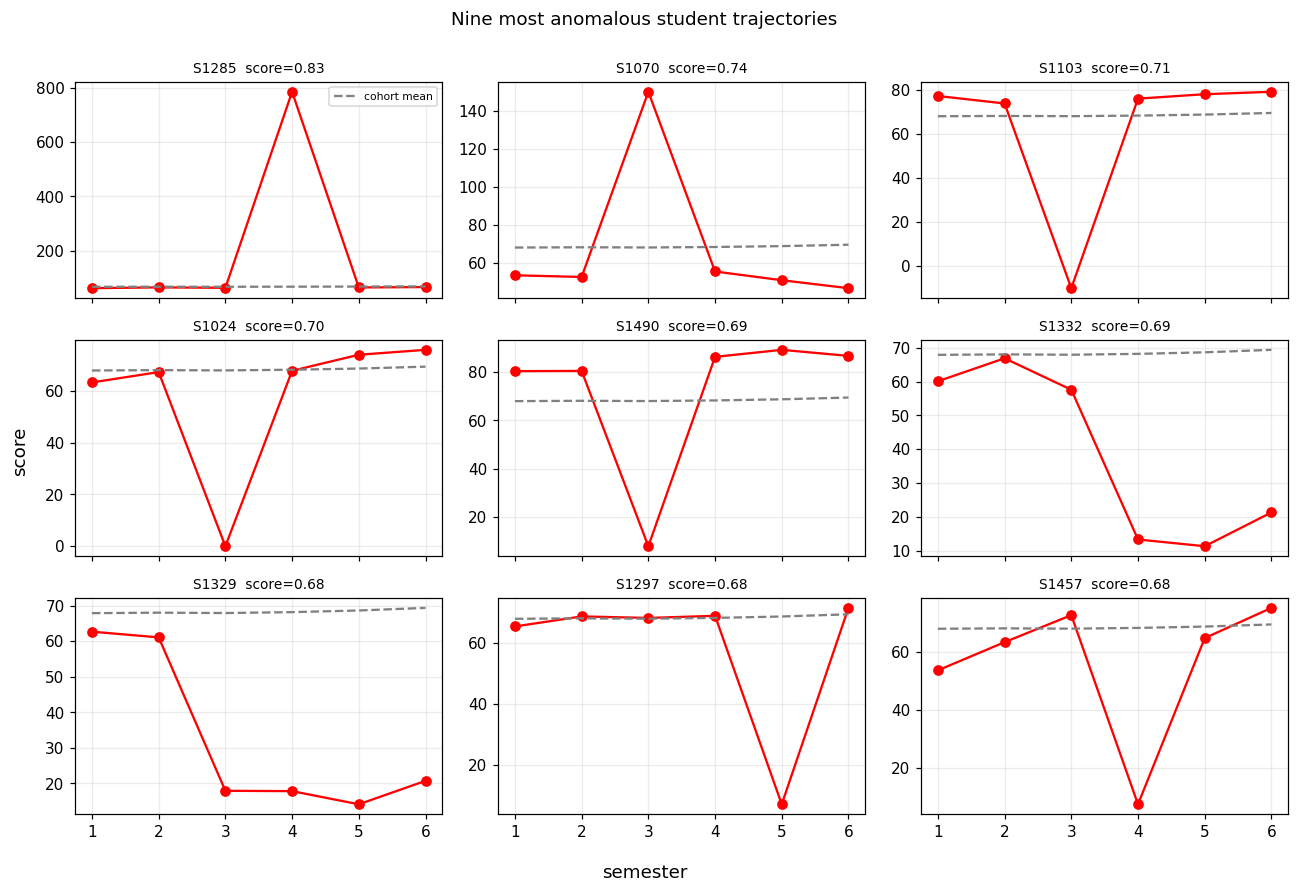

In [8]:
top = np.argsort(score)[::-1][:9]
cohort_mean = df[sem_cols].clip(0, 100).mean().to_numpy()
xs = range(1, len(sem_cols) + 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for ax, i in zip(axes.ravel(), top):
    ax.plot(xs, X[i], "o-", color="red")
    ax.plot(xs, cohort_mean, "--", color="gray", label="cohort mean")
    ax.set_title(f"{df.iloc[i]['student_id']}  score={score[i]:.2f}", fontsize=9)
axes[0, 0].legend(fontsize=7)
fig.supxlabel("semester"); fig.supylabel("score")
fig.suptitle("Nine most anomalous student trajectories", y=1.0)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/top_anomalies.png", dpi=150); plt.show()

## 7. Evaluation

precision    0.967
recall       0.967
F1           0.967
ROC-AUC      1.000
PR-AUC       0.995

TP=29  FP=1  FN=1  TN=469


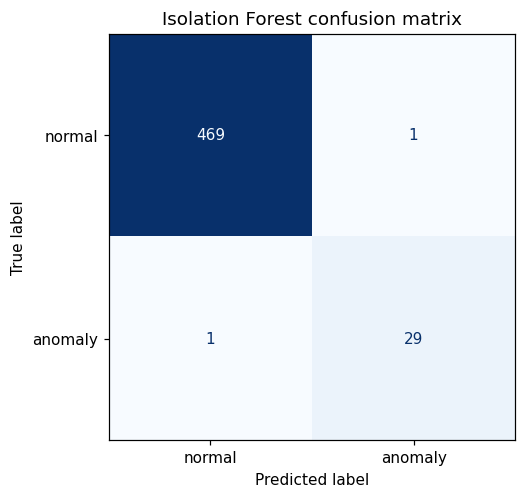


Detected by anomaly type:


,detected,injected
kind,,
digit_swap,5,6
entry_error,6,6
flatline,4,4
sudden_drop,10,10
sudden_spike,3,3
zigzag,1,1


In [9]:
if y_true is None:
    print("No ground-truth labels for real data, so evaluate by manual review.")
    print("Check the top-ranked students above and compare them with the rule-based flags.")
else:
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    summary = pd.Series({
        "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score),
    }).round(3)
    print(summary.to_string())
    print(f"\nTP={tp}  FP={fp}  FN={fn}  TN={tn}")
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred),
                           display_labels=["normal", "anomaly"]).plot(cmap="Blues", colorbar=False)
    plt.title("Isolation Forest confusion matrix"); plt.grid(False); plt.show()

    print("\nDetected by anomaly type:")
    by_type = pd.DataFrame({"kind": kinds, "flagged": pred})
    by_type = by_type[by_type.kind != "normal"].groupby("kind")["flagged"].agg(["sum", "count"])
    by_type.columns = ["detected", "injected"]
    display(by_type)

## 8. Sensitivity to `contamination`, and comparison with Local Outlier Factor

Two checks that strengthen the evaluation: (1) how precision and recall change with the `contamination` parameter, and (2) how Isolation Forest compares with **Local Outlier Factor (LOF)** as a baseline method.

,contamination,precision,recall,f1
0,0.02,1.000,0.333,0.500
1,0.04,1.000,0.667,0.800
2,0.06,0.967,0.967,0.967
3,0.08,0.750,1.000,0.857
4,0.10,0.600,1.000,0.750
5,0.15,0.400,1.000,0.571


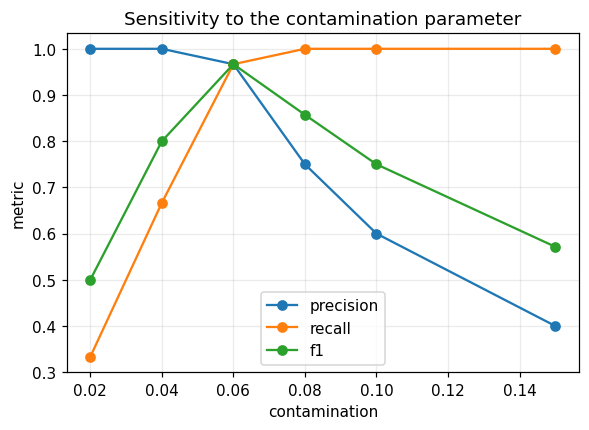

,Isolation Forest,Local Outlier Factor
precision,0.967,0.933
recall,0.967,0.933
F1,0.967,0.933
ROC-AUC,1.000,0.993


In [10]:
if y_true is not None:
    rows = []
    for c in [0.02, 0.04, 0.06, 0.08, 0.10, 0.15]:
        p = (IsolationForest(n_estimators=N_ESTIMATORS, contamination=c, random_state=SEED,
                             n_jobs=-1).fit_predict(Z) == -1).astype(int)
        rows.append((c, precision_score(y_true, p), recall_score(y_true, p), f1_score(y_true, p)))
    sens = pd.DataFrame(rows, columns=["contamination", "precision", "recall", "f1"])
    display(sens.round(3))

    plt.figure(figsize=(6, 4))
    for m in ["precision", "recall", "f1"]:
        plt.plot(sens["contamination"], sens[m], marker="o", label=m)
    plt.xlabel("contamination"); plt.ylabel("metric"); plt.legend()
    plt.title("Sensitivity to the contamination parameter")
    plt.savefig(f"{OUT_DIR}/contamination_sensitivity.png", dpi=150); plt.show()

    # Baseline: Local Outlier Factor
    lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION)
    lof_pred = (lof.fit_predict(Z) == -1).astype(int)
    lof_score = -lof.negative_outlier_factor_
    comparison = pd.DataFrame({
        "Isolation Forest": [precision_score(y_true, pred), recall_score(y_true, pred),
                             f1_score(y_true, pred), roc_auc_score(y_true, score)],
        "Local Outlier Factor": [precision_score(y_true, lof_pred), recall_score(y_true, lof_pred),
                                 f1_score(y_true, lof_pred), roc_auc_score(y_true, lof_score)],
    }, index=["precision", "recall", "F1", "ROC-AUC"]).round(3)
    display(comparison)

## 9. Interpretation of results

Isolation Forest scores are not self-explanatory, so for each top-ranked student we list the features that deviate most from the cohort (largest absolute z-score). This explains *why* a trajectory looked unusual, for example a huge `max_abs_jump` for an abrupt drop, or `n_repeats` and a near-zero `std` for a flatline.

In [11]:
zf = (feats - feats.mean()) / feats.std().replace(0, 1)
rows = []
for i in np.argsort(score)[::-1][:10]:
    t3 = zf.iloc[i].abs().sort_values(ascending=False).head(3).index
    rows.append({
        "student_id": df.iloc[i]["student_id"],
        "score": round(float(score[i]), 3),
        "scores": df.iloc[i][sem_cols].tolist(),
        "main_reasons": ", ".join(f"{n} (z={zf.iloc[i][n]:+.1f})" for n in t3),
        **({"true_type": kinds[i]} if kinds is not None else {}),
    })
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,student_id,score,scores,main_reasons,true_type
0,S1285,0.835,"[62.7, 65.7, 64.1, 785.0, 65.4, 66.8]","max_resid (z=+21.5), max_abs_jump (z=+21.3), std (z=+21.2)",entry_error
1,S1070,0.741,"[53.3, 52.4, 150.0, 55.3, 50.7, 46.5]","max_resid (z=+2.7), range (z=+2.7), mean_abs_jump (z=+2.7)",entry_error
2,S1103,0.715,"[77.1, 73.7, -10.0, 75.9, 77.9, 79.0]","min (z=-5.2), max_resid (z=+2.4), range (z=+2.3)",entry_error
3,S1024,0.695,"[63.3, 67.3, 0.0, 67.8, 74.0, 75.9]","min (z=-4.5), slope (z=+2.0), range (z=+1.9)",entry_error
4,S1490,0.693,"[80.3, 80.4, 8.0, 86.2, 89.1, 86.6]","min (z=-3.9), max_resid (z=+2.0), range (z=+2.0)",digit_swap
5,S1332,0.687,"[60.1, 66.9, 57.6, 13.3, 11.3, 21.3]","slope (z=-6.0), first_last_diff (z=-4.7), min (z=-3.7)",sudden_drop
6,S1329,0.681,"[62.7, 61.1, 17.9, 17.8, 14.1, 20.7]","slope (z=-5.2), first_last_diff (z=-5.1), min (z=-3.5)",sudden_drop
7,S1297,0.680,"[65.4, 68.7, 68.2, 68.9, 7.0, 71.5]","min (z=-4.0), slope (z=-2.4), max_abs_jump (z=+1.6)",digit_swap
8,S1457,0.676,"[53.6, 63.3, 72.6, 7.5, 64.7, 75.1]","min (z=-3.9), first_last_diff (z=+2.3), mean_abs_jump (z=+1.9)",entry_error
9,S1320,0.670,"[96.6, 54.6, 94.6, 56.6, 98.6, 58.6]","first_last_diff (z=-4.6), mean_abs_jump (z=+2.7), slope (z=-1.5)",zigzag


## 10. Export results

In [12]:
results.to_csv(f"{OUT_DIR}/anomaly_results.csv", index=False)
flagged = results[results["is_anomaly"] == 1]
flagged.to_csv(f"{OUT_DIR}/flagged_students.csv", index=False)
print(f"Saved {len(results)} scored students and {len(flagged)} flagged students to {OUT_DIR}")
print(sorted(os.listdir(OUT_DIR)))

Saved 500 scored students and 30 flagged students to /kaggle/working
['__notebook__.ipynb', 'anomaly_results.csv', 'contamination_sensitivity.png', 'flagged_students.csv', 'score_and_pca.png', 'top_anomalies.png']


## 11. Conclusion, limitations and future work

**Conclusion.** Trajectory-level feature engineering combined with Isolation Forest separates unusual score histories (abrupt changes, flatlines, erratic patterns) and likely data-entry errors (impossible values, transposed digits) from normal students. Combining the model with simple rule-based checks covers both statistical outliers and definite errors.

**Limitations**
- On synthetic data the injected anomalies are fairly obvious, so the reported metrics are optimistic. Results on real data need manual validation.
- `contamination` must be chosen in advance and strongly affects the precision/recall trade-off (Section 8).
- Plausible-looking typos, such as a digit swap that keeps the score within the student's normal range, are hard to detect from scores alone.
- A flagged student is a *candidate for review*, not proof of an error. A genuine sudden improvement is also an outlier.

**Future work**
- Validate on a real dataset such as the UCI Student Performance data, with manual review of flagged records.
- Compare with One-Class SVM and autoencoders; add subject-level features.
- Use SHAP-style attribution for richer per-student explanations.
- Add a review dashboard that lets faculty confirm or dismiss flagged records.